# Card 04 – Branches, channels & delivery
**Question:** which branch or channel creates value, and is delivery a real problem?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

files = pd.read_pickle('../clean/cottonil_clean.pkl')

# 3 colours only: navy = main, light grey = context, teal = the ONE thing each chart wants you to look at
NAVY, GREY, TEAL = '#2F4B7C', '#D5DCE6', '#3AA6A0'
BLUE, ORANGE, AQUA, LIGHT = NAVY, TEAL, TEAL, GREY      # old names kept so every notebook uses the same 3 colours
INK = '#4A5568'                                           # text only
plt.rcParams.update({'font.size': 10.5, 'axes.titlesize': 12.5, 'axes.titleweight': 'bold', 'axes.edgecolor': '#d6d5d0',
                     'axes.labelcolor': INK, 'xtick.color': INK, 'ytick.color': INK, 'figure.dpi': 110})


def style(ax, title, ylabel=None):
    """Title = the insight, light grid, no box."""
    ax.set_title(title, loc='left', pad=12)
    for s in ['top', 'right']:
        ax.spines[s].set_visible(False)
    ax.grid(axis='y', color='#ecebe7'); ax.set_axisbelow(True)
    if ylabel:
        ax.set_ylabel(ylabel)


def save(fig, name):
    fig.savefig(f'../outputs/charts/{name}.png', dpi=150, bbox_inches='tight')


def full_years(d, col='fy'):
    """Complete fiscal years only: FY2019 → FY2026 (Oct–Sep)."""
    return d[(d[col] >= 2019) & (d[col] <= 2026)]


M = lambda x: f'{x / 1e6:,.1f}M'

lowest 1.6M | highest 2.1M | coefficient of variation 4.9%


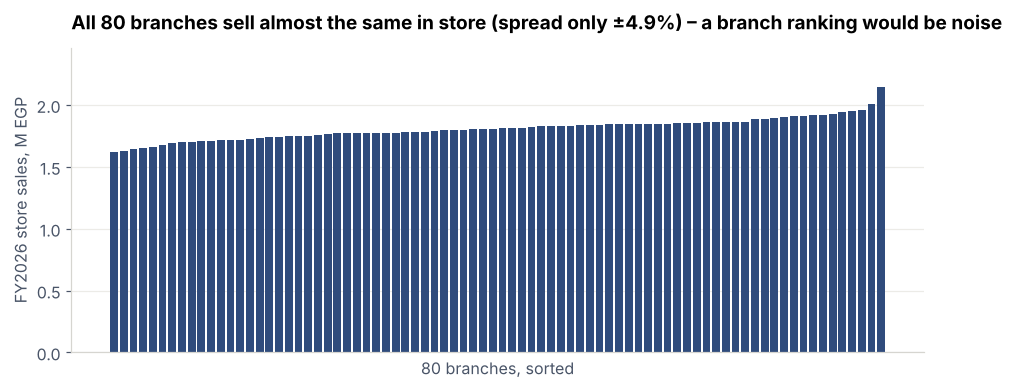

In [2]:
so, br = full_years(files['orders']), files['branches']
b = so[(so.fy == 2026) & (so.channel == 'Store')].groupby('branch_id').net_before_tax_EGP.sum().sort_values()
cv = b.std() / b.mean() * 100
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(range(len(b)), b / 1e6, color=BLUE)
ax.set_ylim(0, b.max() / 1e6 * 1.15); ax.set_xticks([])
style(ax, f'All 80 branches sell almost the same in store (spread only ±{cv:.1f}%) – a branch ranking would be noise', 'FY2026 store sales, M EGP')
ax.set_xlabel('80 branches, sorted')
save(fig, 'c04_branch_parity')
print(f'lowest {M(b.min())} | highest {M(b.max())} | coefficient of variation {cv:.1f}%')

In [3]:
t = so.merge(br[['branch_id', 'retail_location_type', 'governorate_ar']], on='branch_id')
print('orders per branch by type:', (t.groupby('retail_location_type').sales_order_id.size() / t.groupby('retail_location_type').branch_id.nunique()).round(0).to_dict())
pre = files['orders'].before_opening
print(f'orders dated before their branch opened: {pre.sum():,} ({pre.mean():.1%}) in {files["orders"].loc[pre, "branch_id"].nunique()} branches')
print('online and wholesale orders also carry a branch_id in all', so[so.channel != 'Store'].branch_id.nunique(), 'branches')

orders per branch by type: {'Point of sale / reseller': 6709.0, 'Retail branch': 6683.0}
orders dated before their branch opened: 38,040 (7.0%) in 80 branches
online and wholesale orders also carry a branch_id in all 80 branches


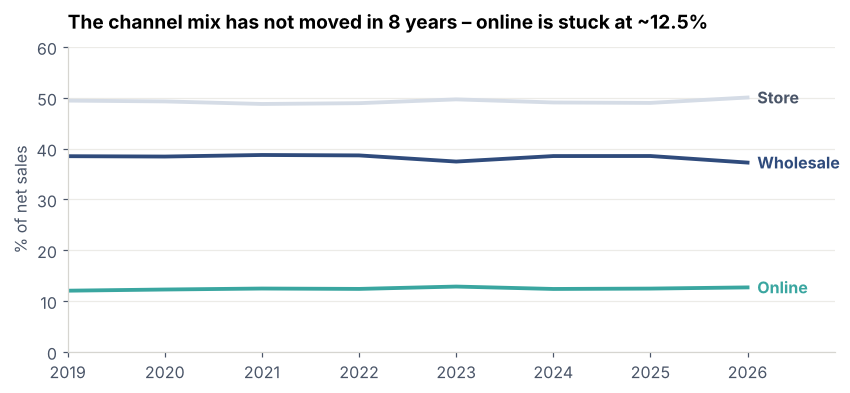

fy,2019,2020,2021,2022,2023,2024,2025,2026
channel,,,,,,,,
Online,12.0,12.3,12.5,12.4,12.9,12.4,12.5,12.7
Store,49.4,49.3,48.8,48.9,49.7,49.1,49.0,50.1
Wholesale,38.5,38.4,38.7,38.7,37.5,38.5,38.5,37.3


In [4]:
share = so.groupby(['fy', 'channel']).net_before_tax_EGP.sum().unstack()
share = share.div(share.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(9, 3.6))
for ch_, color in [('Store', GREY), ('Wholesale', BLUE), ('Online', ORANGE)]:
    ax.plot(share.index, share[ch_], color=color, lw=2.5)
    ax.text(share.index[-1] + 0.1, share[ch_].iloc[-1], ch_, color=INK if color == GREY else color, va='center', fontweight='bold')
ax.set_ylim(0, 60); ax.set_xlim(2019, 2026.9)
style(ax, 'The channel mix has not moved in 8 years – online is stuck at ~12.5%', '% of net sales')
save(fig, 'c04_channel_mix')
share.round(1).T

In [5]:
sh = full_years(files['shipments'])
print('delivery days by governorate:', sh.groupby('ship_to_governorate').delivery_days.mean().agg(['min', 'max']).round(2).to_dict())
print('share of each delivery time (1–7 days):', (sh.delivery_days.value_counts(normalize=True).sort_index() * 100).round(1).to_dict())
pd.crosstab(sh.delivery_days, sh.fulfillment_status, normalize='index').mul(100).round(1).T

delivery days by governorate: {'min': 3.93, 'max': 4.06}
share of each delivery time (1–7 days): {1: 14.2, 2: 14.5, 3: 14.1, 4: 14.5, 5: 14.2, 6: 14.2, 7: 14.3}


delivery_days,1,2,3,4,5,6,7
fulfillment_status,,,,,,,
Delayed,3.1,2.9,3.4,2.9,3.1,3.0,2.9
Delivered,96.9,97.1,96.6,97.1,96.9,97.0,97.1


Delivery time is spread evenly 1–7 days in every governorate (Aswan = Cairo), and "Delayed" is 3% whatever the time.
These fields were filled at random → **no delivery KPI** until real carrier scans exist.

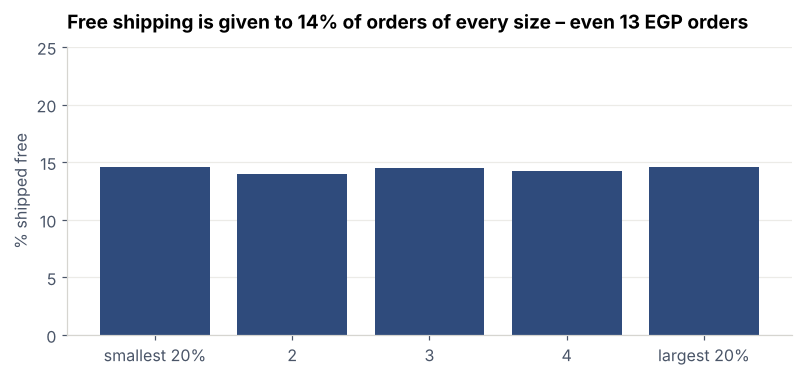

,free only above (EGP),free shipments below it,fees recovered / year (EGP)
0,500,428,25608
1,1000,973,58216
2,1500,1439,86097


In [6]:
sh['order_size'] = pd.qcut(sh.net_before_tax_EGP, 5, labels=['smallest 20%', '2', '3', '4', 'largest 20%'])
free = sh.groupby('order_size', observed=True).free_shipping.mean() * 100
fig, ax = plt.subplots(figsize=(8.5, 3.4))
ax.bar(free.index.astype(str), free, color=BLUE)
ax.set_ylim(0, 25)
style(ax, 'Free shipping is given to 14% of orders of every size – even 13 EGP orders', '% shipped free')
save(fig, 'c04_free_shipping')
s26 = sh[sh.fy == 2026]
avg_fee = s26.loc[~s26.free_shipping, 'shipping_fee_EGP'].mean()
rows = []
for th in [500, 1000, 1500]:
    lost = s26[s26.free_shipping & (s26.net_before_tax_EGP < th)]
    rows.append({'free only above (EGP)': th, 'free shipments below it': len(lost), 'fees recovered / year (EGP)': round(len(lost) * avg_fee)})
pd.DataFrame(rows)

In [7]:
rt = full_years(files['returns'])
r = rt.groupby('fy').refund_amount_EGP.sum() / so.groupby('fy').net_before_tax_EGP.sum() * 100
print('refunds as % of sales by year:', r.round(2).to_dict())
(rt.reason.value_counts(normalize=True) * 100).round(1).to_frame('% of returns')

refunds as % of sales by year: {2019: 1.6, 2020: 1.79, 2021: 1.61, 2022: 1.73, 2023: 1.62, 2024: 1.59, 2025: 1.55, 2026: 1.71}


,% of returns
reason,
Other,20.3
Size issue,20.2
Defect claim,19.9
Wrong item,19.8
Exchange,19.8


### Takeaway (card 04)
- **Branches:** FY2026 store sales per branch differ by only ±5% (coefficient of variation) → ranking branches or picking a new location from this data would be noise (honest limit).
  7% of orders are dated before their branch opened → the opening dates must be confirmed.
- **Channels:** frozen mix (Store 50%, Wholesale 38%, Online 12.5%). Wholesale orders are ~24 pieces vs ~4.3.
- **Delivery:** time and "Delayed" are random → not a KPI. **Free shipping** is random (14% of all order sizes); a minimum-order rule is free money (small: ~0.1M EGP/yr) and good discipline.
- **Returns:** refunds are a stable ~1.6% of sales; reasons are 20% each → reasons need a real capture form.